In [1]:
import numpy as np
import numpy.random as rand
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [4]:
rng = rand.default_rng(10)
x1 = rng.uniform(0, 1, size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)

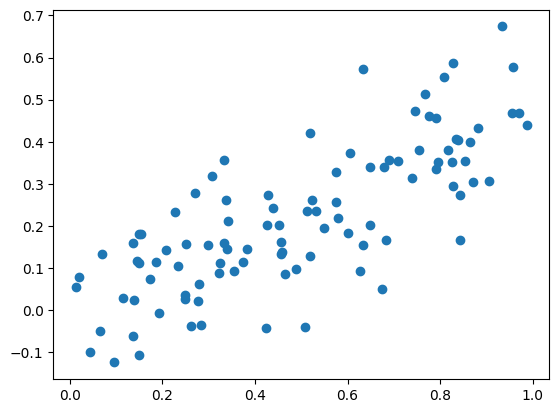

In [8]:
plt.scatter(x1, x2)
plt.show()

In [6]:
from scipy.stats import t

model = LinearRegression()
X = np.column_stack((x1, x2))
model.fit(X, y)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

n, p = X.shape
y_pred = model.predict(X)
residuals = y - y_pred
rss = np.sum(residuals**2)
sigma_squared = rss / (n - p - 1)
X_with_intercept = np.column_stack((np.ones(n), X))
XtX_inv = np.linalg.inv(X_with_intercept.T @ X_with_intercept)
se = np.sqrt(np.diag(sigma_squared * XtX_inv))
t_stats = model.coef_ / se[1:]
p_values = 2 * (1 - t.cdf(np.abs(t_stats), df=n - p - 1))

for i, p_val in enumerate(p_values, start=1):
    print(f"H0: β{i} = 0, p-value: {p_val}")

Coefficients: [1.6153677 0.9427767]
Intercept: 1.957909291136691
H0: β1 = 0, p-value: 0.002815785183782449
H0: β2 = 0, p-value: 0.2594185944524492


In [ ]:
model = LinearRegression()
model.fit(x1.reshape(-1, 1), y)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

rss_new = np.sum((y - model.predict(x1.reshape(-1, 1)))**2)
sigma_squared_new = rss_new / (n - 1)
se_new = np.sqrt(sigma_squared_new / np.sum((x1 - np.mean(x1))**2))
t_stat_new = model.coef_[0] / se_new
p_value_new = 2 * (1 - t.cdf(np.abs(t_stat_new), df=n - 1))
print("p-value:", p_value_new)

Coefficient: [2.07706235]
Intercept: 1.9370901533116103
p-value: 1.1538816346856606e-08


In [9]:
model = LinearRegression()
model.fit(x2.reshape(-1, 1), y)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

rss_new = np.sum((y - model.predict(x1.reshape(-1, 1)))**2)
sigma_squared_new = rss_new / (n - 1)
se_new = np.sqrt(sigma_squared_new / np.sum((x1 - np.mean(x1))**2))
t_stat_new = model.coef_[0] / se_new
p_value_new = 2 * (1 - t.cdf(np.abs(t_stat_new), df=n - 1))
print("p-value:", p_value_new)

Coefficient: [2.91032323]
Intercept: 2.323890012497929
p-value: 4.9608082086649574e-09


In [ ]:
x1 = rng.uniform(0, 1, size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)

x1 = np.concatenate([x1, [0.1]])
x2 = np.concatenate([x2, [0.8]])
y = np.concatenate([y, [6.0]])

In [17]:
model = LinearRegression()
X = np.column_stack((x1, x2))
model.fit(X, y)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [1.25744752 1.60899889]
Intercept: 1.9931501596016241


In [18]:
model = LinearRegression()
model.fit(x1.reshape(-1, 1), y)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [2.07666797]
Intercept: 1.9831931501777171


In [19]:
model = LinearRegression()
model.fit(x2.reshape(-1, 1), y)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [3.00394078]
Intercept: 2.253883589330846
